In [1]:
import sys
from pathlib import Path

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Find project root
PROJECT_DIR = Path.cwd().resolve()

if PROJECT_DIR.name == "notebooks":
    PROJECT_DIR = PROJECT_DIR.parent

sys.path.insert(0, str(PROJECT_DIR))

from src.fao56 import calculate_et0

DATA_DIR = PROJECT_DIR / "data"
RESULTS_DIR = PROJECT_DIR / "results"

RESULTS_DIR.mkdir(exist_ok=True)

print("Project:", PROJECT_DIR)
print("FAO-56 module imported successfully!")

Project: D:\Documents\artificial_intelligence\Smart_Irrigation
FAO-56 module imported successfully!


In [2]:
# Load growing season dataset

df = pd.read_csv(
    DATA_DIR / "weather_growing_season.csv",
    parse_dates=["time"]
)

print("Dataset loaded successfully!")
print("Shape:", df.shape)
print("Columns:", df.columns.tolist())

display(df.head())

Dataset loaded successfully!
Shape: (918, 8)
Columns: ['time', 'temperature_2m_max', 'temperature_2m_min', 'temperature_2m_mean', 'precipitation_sum', 'wind_speed_10m_mean', 'shortwave_radiation_sum', 'relative_humidity_2m']


,time,temperature_2m_max,temperature_2m_min,temperature_2m_mean,precipitation_sum,wind_speed_10m_mean,shortwave_radiation_sum,relative_humidity_2m
0,2020-05-01,23.0,8.9,16.0,0.0,1.58,25.27,64.833333
1,2020-05-02,21.2,12.4,16.3,3.5,1.96,17.02,71.041667
2,2020-05-03,22.6,11.7,16.2,4.9,3.59,18.96,72.416667
3,2020-05-04,23.8,11.5,17.7,0.0,2.66,25.66,58.708333
4,2020-05-05,20.5,10.4,15.4,0.1,2.66,19.21,64.916667


In [3]:
# Calculate daily reference evapotranspiration

df["day_of_year"] = df["time"].dt.day_of_year

df["et0"] = df.apply(
    lambda row: calculate_et0(
        t_min=row["temperature_2m_min"],
        t_max=row["temperature_2m_max"],
        t_mean=row["temperature_2m_mean"],
        relative_humidity=row["relative_humidity_2m"],
        solar_radiation=row["shortwave_radiation_sum"],
        wind_speed_10m=row["wind_speed_10m_mean"],
        latitude=42.8746,
        elevation=800,
        day_of_year=int(row["day_of_year"])
    ),
    axis=1
)

print("ET0 calculated successfully!")
print("ET0 column exists:", "et0" in df.columns)
print("Total ET0 values:", df["et0"].count())

display(df[["time", "et0"]].head())

ET0 calculated successfully!
ET0 column exists: True
Total ET0 values: 918


,time,et0
0,2020-05-01,4.176293
1,2020-05-02,3.248464
2,2020-05-03,3.882313
3,2020-05-04,4.789880
4,2020-05-05,3.644162


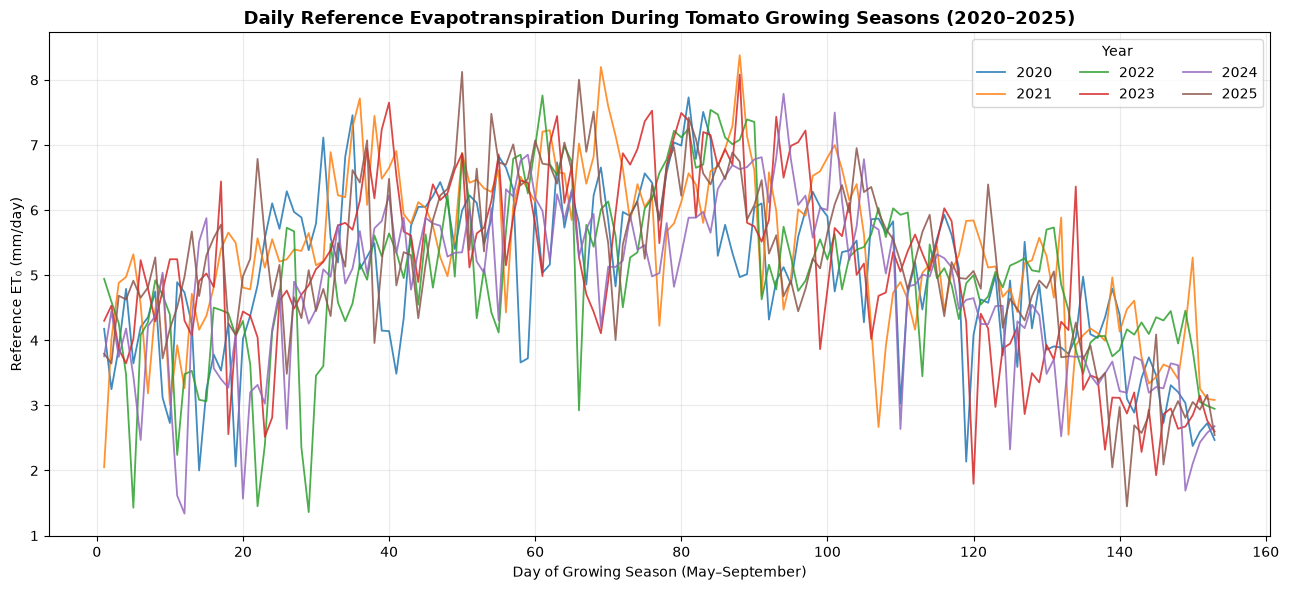

In [4]:
# ==========================================
# ET0 Visualization by Growing Season
# ==========================================

import matplotlib.pyplot as plt

df["time"] = pd.to_datetime(df["time"])
df["year"] = df["time"].dt.year
df["season_day"] = df["time"].dt.day_of_year - (
    pd.to_datetime(df["year"].astype(str) + "-05-01")
    .dt.day_of_year
) + 1

plt.figure(figsize=(13, 6))

for year, group in df.groupby("year"):
    plt.plot(
        group["season_day"],
        group["et0"],
        label=str(year),
        linewidth=1.3,
        alpha=0.85
    )

plt.title(
    "Daily Reference Evapotranspiration During "
    "Tomato Growing Seasons (2020–2025)",
    fontsize=13,
    fontweight="bold"
)

plt.xlabel("Day of Growing Season (May–September)")
plt.ylabel("Reference ET₀ (mm/day)")
plt.legend(title="Year", ncol=3)
plt.grid(alpha=0.25)
plt.tight_layout()

plt.savefig(
    RESULTS_DIR / "et0_growing_seasons.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()

In [5]:
output_file = DATA_DIR / "weather_with_et0.csv"

df.to_csv(output_file, index=False)

print("ET0 dataset saved successfully!")
print("File:", output_file)
print("Total records:", len(df))
print("Missing ET0 values:", df["et0"].isna().sum())

ET0 dataset saved successfully!
File: D:\Documents\artificial_intelligence\Smart_Irrigation\data\weather_with_et0.csv
Total records: 918
Missing ET0 values: 0


In [6]:
# ==========================================
# ET0 Validation
# ==========================================

import numpy as np

print("FAO-56 ET0 VALIDATION")
print("=" * 45)

print("Total observations:", len(df))
print("Missing ET0 values:", df["et0"].isna().sum())
print("Negative ET0 values:", (df["et0"] < 0).sum())
print("Infinite ET0 values:", np.isinf(df["et0"]).sum())

print("\nET0 Statistics:")
print(df["et0"].describe().round(3))

assert df["et0"].notna().all()
assert np.isfinite(df["et0"]).all()
assert (df["et0"] >= 0).all()

print("\nBasic ET0 data checks: PASSED")

FAO-56 ET0 VALIDATION
Total observations: 918
Missing ET0 values: 0
Negative ET0 values: 0
Infinite ET0 values: 0

ET0 Statistics:
count    918.000
mean       5.094
std        1.312
min        1.338
25%        4.250
50%        5.162
75%        6.035
max        8.378
Name: et0, dtype: float64

Basic ET0 data checks: PASSED


In [7]:
# Additional growing-season validation

assert len(df) == 918, "Unexpected growing season size"

assert df["time"].dt.month.between(5, 9).all(), (
    "Dataset contains dates outside the growing season"
)

assert df["time"].is_unique, "Duplicate dates detected"

assert "et0" in df.columns, "ET0 column is missing"

print("\nGrowing season validation: PASSED")
print("Total growing season records:", len(df))
print("Mean ET0:", round(df["et0"].mean(), 3), "mm/day")


Growing season validation: PASSED
Total growing season records: 918
Mean ET0: 5.094 mm/day


## FAO-56 Penman–Monteith Implementation

The FAO-56 Penman–Monteith model was implemented in Python to estimate daily reference evapotranspiration (ET₀) using historical weather data from Bishkek, Kyrgyzstan.

The model processes daily minimum, maximum, and mean air temperatures, relative humidity, solar radiation, and wind speed.

A total of 918 daily observations covering the May–September growing seasons from 2020 to 2025 were processed.

The average estimated reference evapotranspiration was approximately **5.09 mm/day**.

The calculated values were checked for missing, negative, and infinite results. A comparative visualization was generated for the six growing seasons.

**Limitations:** The current implementation uses an approximate elevation of 800 m and estimates actual vapor pressure using mean relative humidity. Additional validation against reference FAO-56 examples is required before considering the physical model fully validated.